# HOMEWORK 13

In this homework you are going to inspect the GTSRB (German Traffic Sign Recognition Benchmark) dataset. The dataset contains images of various classes of traffic signs used in Germany (and the whole EU). The objective of this homework is to go through the steps described below and to implement the necessary code.

At the end, as usual, there will be a couple of questions for you to answer. In addition, the last section of this homework is optional and, if you chose to do it, you'll earn extra point :-)

In [10]:
import os
import cv2
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

### Step 0

Go to the GTSRB dataset official site ([link](https://benchmark.ini.rub.de/gtsrb_dataset.html)) to learn more about the dataset.

### Step 1

Download the dataset ([link](https://www.kaggle.com/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign)) and unzip it.

### Step 2

For this homework, you will be working with the training set. Check out the `Train.csv`, open it and see what it contains. Load the dataset and plot random samples.

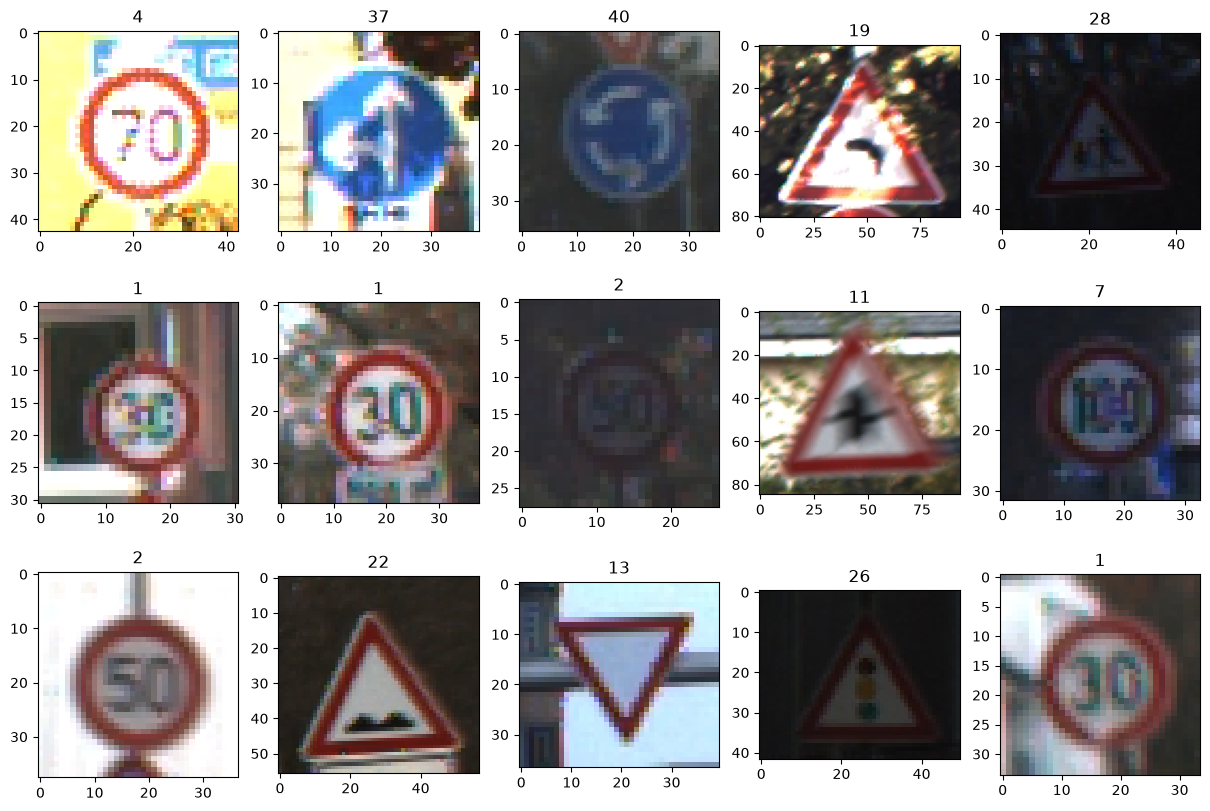

In [11]:
# Load the training labels
root = '/Users/andriizemlianyi/Code/datasets/GTSRB'
data = pd.read_csv(os.path.join(root, 'Train.csv'))

# Number of training samples (amount of samples in data)
num_samples = len(data)  # Кількість рядків у таблиці

# Show random data samples
for ii in range(15):
    # Get random index
    idx = np.random.randint(0, num_samples)
    # Load image
    img = cv2.imread(os.path.join(root, data.iloc[idx]['Path']))
    # Convert image to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # OpenCV читає BGR, переводимо в RGB
    # Show image
    plt.subplot(3,5,ii+1), plt.imshow(img), plt.title(data.iloc[idx]['ClassId'])

### Step 3

Inspect the dataset by computing and plotting the per-class histogram.

In [12]:
# Extract class identifiers
# Hint: Check the csv 
ids = data['ClassId']  # Стовпець з номерами класів

Compute the per class histogram. You can use any approach you want (e.g. `numpy`). It's also worth looking at the `Counter` function from the `collections` module ([link](https://docs.python.org/3/library/collections.html#collections.Counter)) ;-)

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

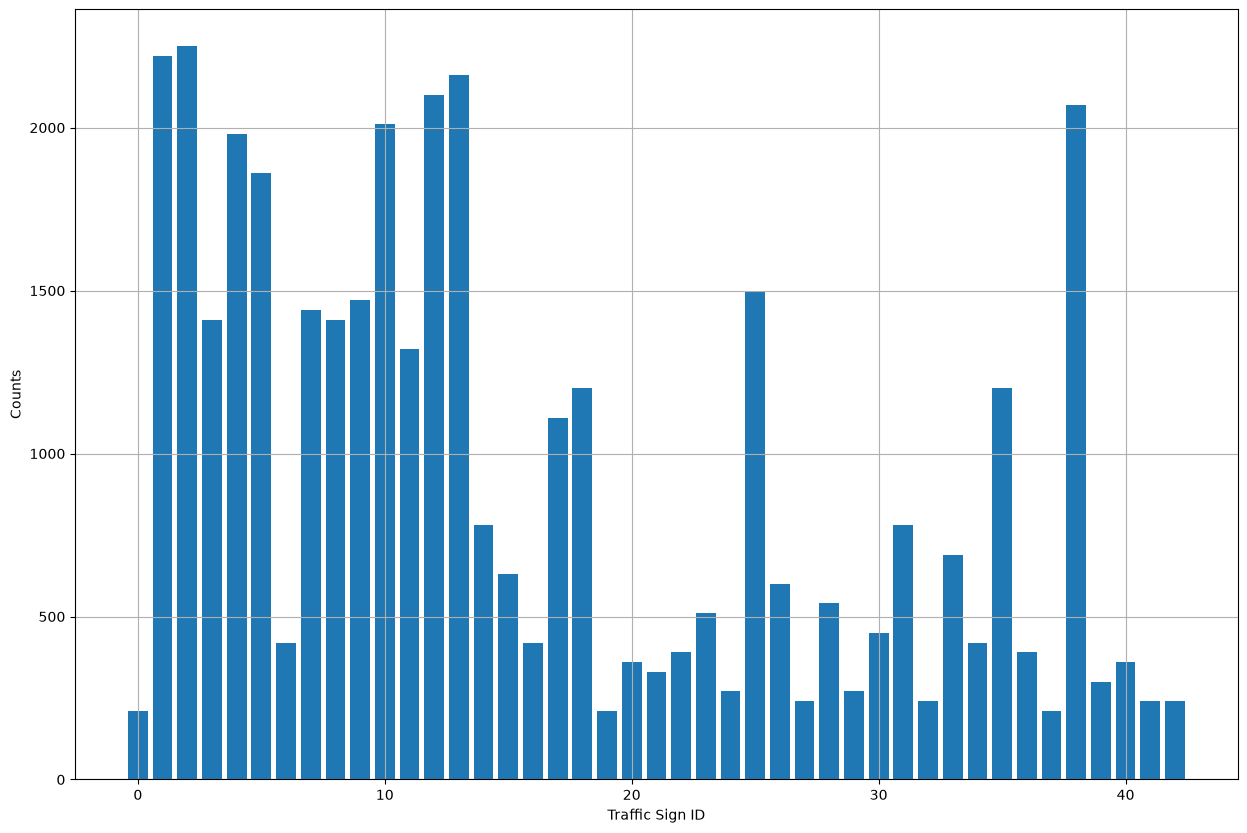

In [13]:
from collections import Counter
hist = Counter(ids)

plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

In [14]:
most_id = max(hist, key=hist.get)
least_id = min(hist, key=hist.get)
print('Найчастіший клас:', most_id, 'кількість:', hist[most_id])
print('Найрідший клас:', least_id, 'кількість:', hist[least_id])
print('Усього зразків:', num_samples)

# Accuracy "класифікатора", що завжди каже найчастіший клас
dummy_acc = hist[most_id] / num_samples
print('Accuracy dummy-класифікатора:', dummy_acc)

Найчастіший клас: 2 кількість: 2250
Найрідший клас: 0 кількість: 210
Усього зразків: 39209
Accuracy dummy-класифікатора: 0.05738478410569002


### Questions

Please answer the following questions:
* Do you consider the dataset to be balanced? If so, why? If not, why?
Ні. Кількість зразків різниться +- в 10 разів між класами.

* Are there any classes that are (significantly) over-represented or under-represented?
Класи до 13 в більшості, а класи 0, 6, 19 і все що далі їх мало.


* What would be the accuracy of a "classifier" that always predicts the most frequent class? What does it tell you about using accuracy as the only metric for this dataset?
5,7%. Це небагато, бо зааглом 43 класи і немає такого який виділяється, треба precision/recall робити по класах щоб була якість.

* The images are `uint8` with values in [0, 255] and they have different sizes. What preprocessing would you apply before feeding them to a neural network (and why)?
Зробити resize до єдиного розміру.

### Optional

Perform a further analysis on the dataset and draw some conclusion from it.

Hint 1: Unlike MNIST or CIFAR10, this dataset contains images with various spatial resolutions. Is there anything we can tell about the resolution distribution?
Розміри 25–243 px, середня 50, більшість знаків малі, тому потрібен resize.

Hint 2: What about the brightness distribution? Are there classes there are significantly more bright than others?
Яскравість різна: класи 6, 10, 17 дуже темні, класи 1, 18, 14 світлі. Стандартизація зменшує вплив освітлення.


Ширина: мін 25 макс 243 середня 50.83587951745773
Висота: мін 25 макс 225 середня 50.328929582493814


(<Axes: xlabel='Height'>,
 (array([1.779e+03, 5.033e+03, 5.316e+03, 4.828e+03, 3.908e+03, 3.234e+03,
         2.643e+03, 2.123e+03, 1.830e+03, 1.438e+03, 6.170e+02, 1.133e+03,
         9.040e+02, 3.600e+02, 6.960e+02, 5.540e+02, 2.620e+02, 4.060e+02,
         3.570e+02, 1.730e+02, 2.910e+02, 2.290e+02, 1.000e+02, 1.890e+02,
         1.570e+02, 6.800e+01, 1.240e+02, 9.600e+01, 3.800e+01, 7.100e+01,
         5.400e+01, 2.200e+01, 4.100e+01, 2.600e+01, 1.200e+01, 2.100e+01,
         1.900e+01, 1.300e+01, 9.000e+00, 6.000e+00, 2.000e+00, 9.000e+00,
         6.000e+00, 2.000e+00, 4.000e+00, 1.000e+00, 1.000e+00, 2.000e+00,
         1.000e+00, 1.000e+00]),
  array([ 25.,  29.,  33.,  37.,  41.,  45.,  49.,  53.,  57.,  61.,  65.,
          69.,  73.,  77.,  81.,  85.,  89.,  93.,  97., 101., 105., 109.,
         113., 117., 121., 125., 129., 133., 137., 141., 145., 149., 153.,
         157., 161., 165., 169., 173., 177., 181., 185., 189., 193., 197.,
         201., 205., 209., 213., 217., 22

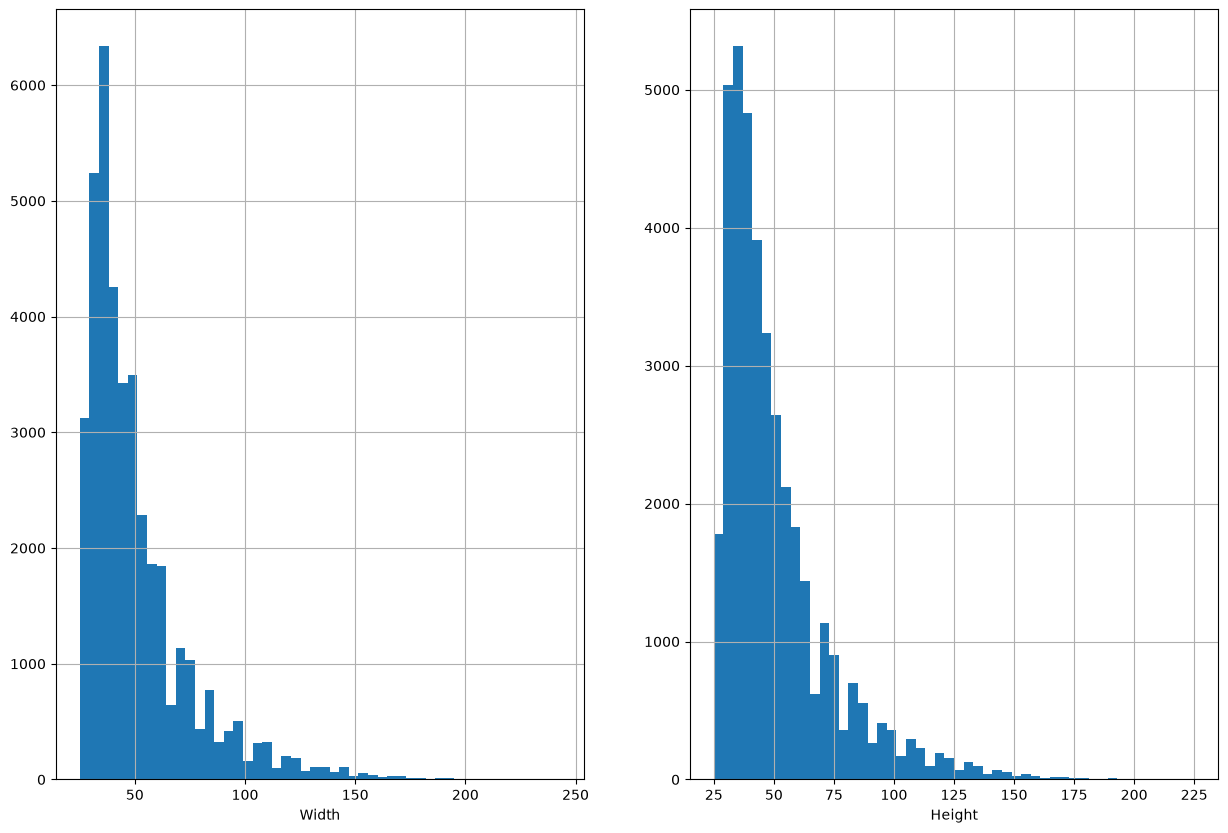

In [15]:
# Розмір зображень: Width і Height беремо з Train.csv
widths = data['Width']
heights = data['Height']
print('Ширина: мін', widths.min(), 'макс', widths.max(), 'середня', widths.mean())
print('Висота: мін', heights.min(), 'макс', heights.max(), 'середня', heights.mean())

plt.subplot(1,2,1), plt.hist(widths, bins=50), plt.xlabel('Width'), plt.grid(True)
plt.subplot(1,2,2), plt.hist(heights, bins=50), plt.xlabel('Height'), plt.grid(True)

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Середня яскравість (0-255)'))

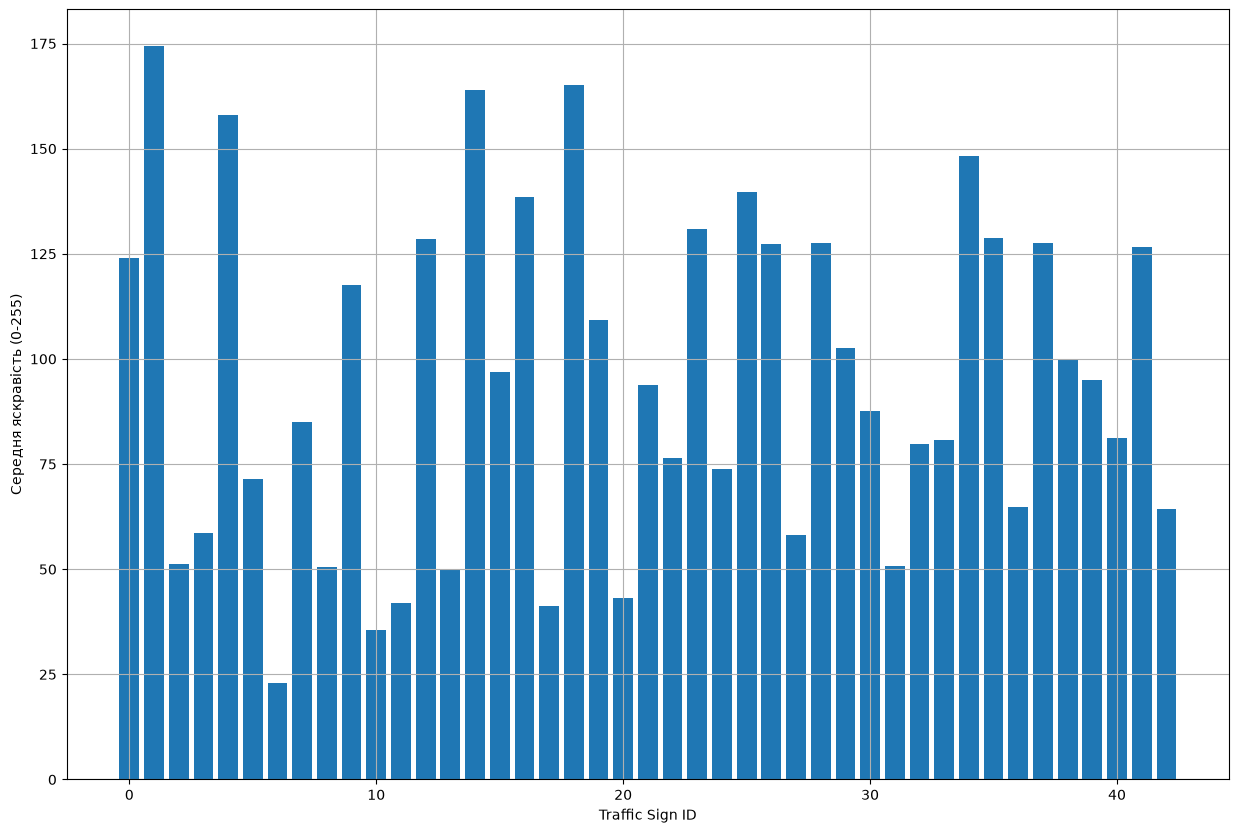

In [16]:
# Середня яскравість по класах (по 50 картинок на клас, щоб було швидко)
class_ids = []
class_brightness = []
for class_id in range(43):
    rows = data[data['ClassId'] == class_id].head(50)
    total = 0
    for path in rows['Path']:
        img = cv2.imread(os.path.join(root, path))
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        total = total + gray.mean()
    class_ids.append(class_id)
    class_brightness.append(total / len(rows))

plt.bar(class_ids, class_brightness), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Середня яскравість (0-255)')